# Exploratory Data Analysis — Shoe Brand Classification

Analisis dataset Adidas, Converse, dan Nike sebelum training. Notebook ini hanya membaca dataset dan tidak mengubah file gambar atau menjalankan training.

In [1]:
from __future__ import annotations

import hashlib
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, UnidentifiedImageError

DATASET_ROOT = Path("../datasets/shoe_brands_preprocessed").resolve()
EXPECTED_SPLITS = ["train", "val", "test"]
EXPECTED_CLASSES = ["adidas", "converse", "nike"]
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
RANDOM_SEED = 37
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

if not DATASET_ROOT.is_dir():
    raise FileNotFoundError(
        f"Dataset not found at {DATASET_ROOT}. Run preprocessing.ipynb first."
    )

print(f"Dataset root: {DATASET_ROOT}")

Dataset root: C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed


## Build image metadata

In [2]:
def calculate_sha256(file_path: Path) -> str:
    digest = hashlib.sha256()
    with file_path.open("rb") as image_file:
        for chunk in iter(lambda: image_file.read(64 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def inspect_image(file_path: Path, split_name: str, class_name: str) -> dict:
    with Image.open(file_path) as image:
        image.load()
        grayscale_pixels = np.asarray(image.convert("L"), dtype=np.float32)
        width, height = image.size
        return {
            "split": split_name,
            "class_name": class_name,
            "path": str(file_path),
            "file_name": file_path.name,
            "file_size_kb": file_path.stat().st_size / 1024,
            "width": width,
            "height": height,
            "aspect_ratio": width / height,
            "image_mode": image.mode,
            "brightness": float(grayscale_pixels.mean()),
            "contrast": float(grayscale_pixels.std()),
            "sha256": calculate_sha256(file_path),
        }


metadata_records = []
corrupt_files = []
for split_name in EXPECTED_SPLITS:
    for class_name in EXPECTED_CLASSES:
        class_directory = DATASET_ROOT / split_name / class_name
        if not class_directory.is_dir():
            continue
        for file_path in sorted(class_directory.iterdir()):
            if not file_path.is_file() or file_path.suffix.lower() not in SUPPORTED_EXTENSIONS:
                continue
            try:
                metadata_records.append(inspect_image(file_path, split_name, class_name))
            except (OSError, UnidentifiedImageError, ValueError) as error:
                corrupt_files.append({"path": str(file_path), "error": str(error)})

metadata = pd.DataFrame(metadata_records)
if metadata.empty:
    raise RuntimeError("No readable images found in the dataset.")

print(f"Readable images: {len(metadata)}")
print(f"Corrupt images: {len(corrupt_files)}")
metadata.head()

Readable images: 825
Corrupt images: 0


,split,class_name,path,file_name,file_size_kb,width,height,aspect_ratio,image_mode,brightness,contrast,sha256
0,train,adidas,C:\my-project\shoe-brand-classifier\modeling\d...,adidas_0000.jpg,16.411133,224,224,1.0,RGB,186.554230,40.846485,2b1a604bca251710707524a0dbcbf227d245befde0ddf0...
1,train,adidas,C:\my-project\shoe-brand-classifier\modeling\d...,adidas_0001.jpg,23.891602,224,224,1.0,RGB,102.755623,54.985374,aaa4c9083a2de2513b14daced16cc8df9dd8525e67d8be...
2,train,adidas,C:\my-project\shoe-brand-classifier\modeling\d...,adidas_0002.jpg,11.833984,224,224,1.0,RGB,225.948227,28.282919,23cd155e07b9c43673bddd432653d791c880cacc713a4e...
3,train,adidas,C:\my-project\shoe-brand-classifier\modeling\d...,adidas_0003.jpg,25.825195,224,224,1.0,RGB,99.401009,49.274273,b048ce0a37c1f25ade0dcf2de8f63bb2b1094fe7f1d908...
4,train,adidas,C:\my-project\shoe-brand-classifier\modeling\d...,adidas_0004.jpg,18.194336,224,224,1.0,RGB,51.930126,69.735420,32129c6a155a9f15104e97f474acccfee17f8abce32290...


## Split and class distribution

In [3]:
distribution = (
    metadata.groupby(["split", "class_name"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=EXPECTED_SPLITS, columns=EXPECTED_CLASSES, fill_value=0)
)
distribution["total"] = distribution.sum(axis=1)
distribution.loc["total"] = distribution.sum(axis=0)
display(distribution)

class_percentages = (
    distribution.loc[EXPECTED_SPLITS, EXPECTED_CLASSES]
    .div(distribution.loc[EXPECTED_SPLITS, "total"], axis=0)
    .mul(100)
    .round(2)
)
formatted_percentages = class_percentages.apply(
    lambda column: column.map(lambda value: f"{value:.2f}%")
)
display(formatted_percentages)

missing_classes = {
    split_name: [class_name for class_name in EXPECTED_CLASSES if distribution.loc[split_name, class_name] == 0]
    for split_name in EXPECTED_SPLITS
}
missing_classes = {split_name: classes for split_name, classes in missing_classes.items() if classes}
if missing_classes:
    print(f"WARNING: splits with missing classes: {missing_classes}")

class_name,adidas,converse,nike,total
split,,,,
train,193,193,193,579
val,55,55,55,165
test,27,27,27,81
total,275,275,275,825


class_name,adidas,converse,nike
split,,,
train,33.33%,33.33%,33.33%
val,33.33%,33.33%,33.33%
test,33.33%,33.33%,33.33%


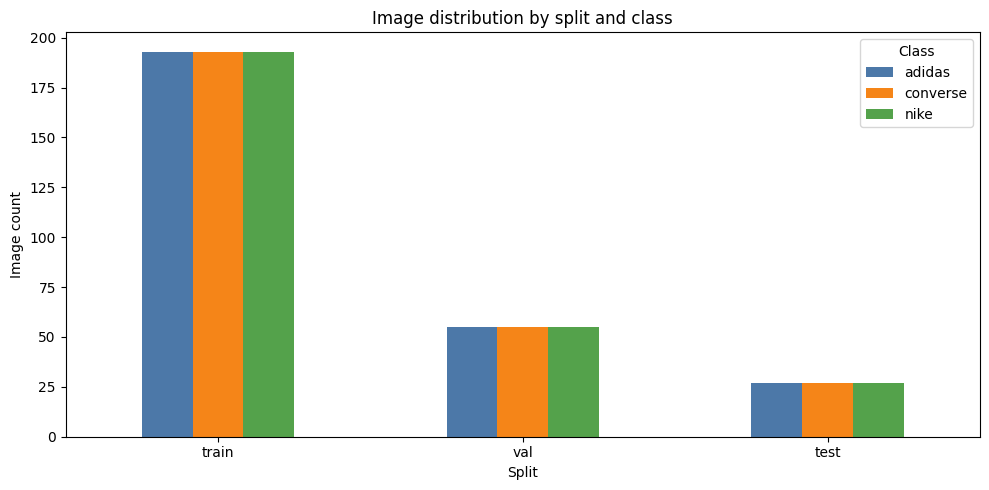

In [4]:
plot_data = distribution.loc[EXPECTED_SPLITS, EXPECTED_CLASSES]
axis = plot_data.plot(kind="bar", figsize=(10, 5), color=["#4C78A8", "#F58518", "#54A24B"])
axis.set_title("Image distribution by split and class")
axis.set_xlabel("Split")
axis.set_ylabel("Image count")
axis.tick_params(axis="x", rotation=0)
axis.legend(title="Class")
plt.tight_layout()
plt.show()

## Image dimensions and file characteristics

In [5]:
dimension_summary = metadata[["width", "height", "aspect_ratio", "file_size_kb"]].describe().round(2)
display(dimension_summary)
display(metadata["image_mode"].value_counts().rename("image_count").to_frame())

resolution_counts = (
    metadata.groupby(["width", "height"]).size().sort_values(ascending=False).rename("image_count")
)
display(resolution_counts.head(10).to_frame())
print(f"Images with 240x240 resolution: {((metadata['width'] == 240) & (metadata['height'] == 240)).sum()} / {len(metadata)}")

,width,height,aspect_ratio,file_size_kb
count,825.0,825.0,825.0,825.00
mean,224.0,224.0,1.0,15.75
std,0.0,0.0,0.0,6.17
min,224.0,224.0,1.0,4.20
25%,224.0,224.0,1.0,10.81
50%,224.0,224.0,1.0,15.19
75%,224.0,224.0,1.0,19.52
max,224.0,224.0,1.0,35.94


,image_count
image_mode,
RGB,825


,,image_count
width,height,
224,224,825


Images with 240x240 resolution: 0 / 825


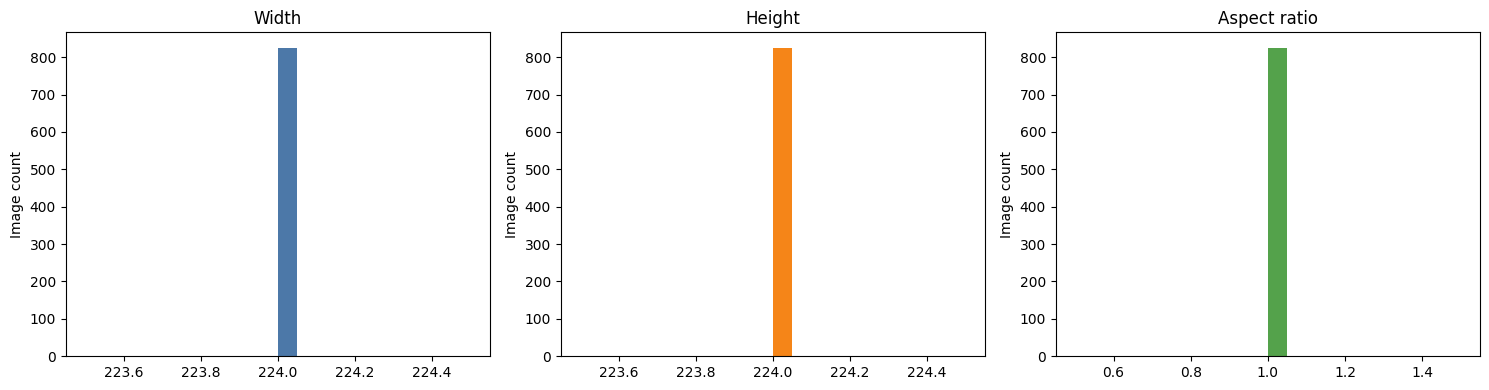

In [6]:
figure, axes = plt.subplots(1, 3, figsize=(15, 4))
metadata["width"].plot(kind="hist", bins=20, ax=axes[0], color="#4C78A8", title="Width")
metadata["height"].plot(kind="hist", bins=20, ax=axes[1], color="#F58518", title="Height")
metadata["aspect_ratio"].plot(kind="hist", bins=20, ax=axes[2], color="#54A24B", title="Aspect ratio")
for axis in axes:
    axis.set_ylabel("Image count")
plt.tight_layout()
plt.show()

## Brightness and contrast

,brightness,contrast
count,825.00,825.00
mean,181.45,56.11
std,47.35,19.02
min,34.56,11.61
25%,140.54,41.83
50%,196.49,57.13
75%,222.12,69.27
max,249.71,107.04


1st percentile brightness: 76.33
99th percentile brightness: 245.48
Darkest percentile images: 9
Brightest percentile images: 9


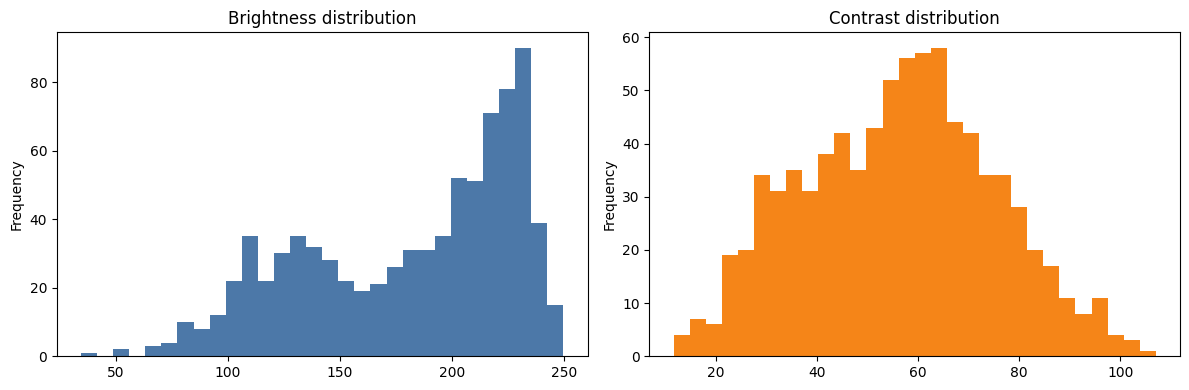

In [7]:
display(metadata[["brightness", "contrast"]].describe().round(2))

brightness_limits = metadata["brightness"].quantile([0.01, 0.99])
dark_images = metadata[metadata["brightness"] <= brightness_limits.loc[0.01]]
bright_images = metadata[metadata["brightness"] >= brightness_limits.loc[0.99]]
print(f"1st percentile brightness: {brightness_limits.loc[0.01]:.2f}")
print(f"99th percentile brightness: {brightness_limits.loc[0.99]:.2f}")
print(f"Darkest percentile images: {len(dark_images)}")
print(f"Brightest percentile images: {len(bright_images)}")

figure, axes = plt.subplots(1, 2, figsize=(12, 4))
metadata["brightness"].plot(kind="hist", bins=30, ax=axes[0], color="#4C78A8", title="Brightness distribution")
metadata["contrast"].plot(kind="hist", bins=30, ax=axes[1], color="#F58518", title="Contrast distribution")
plt.tight_layout()
plt.show()

## Sample visualization

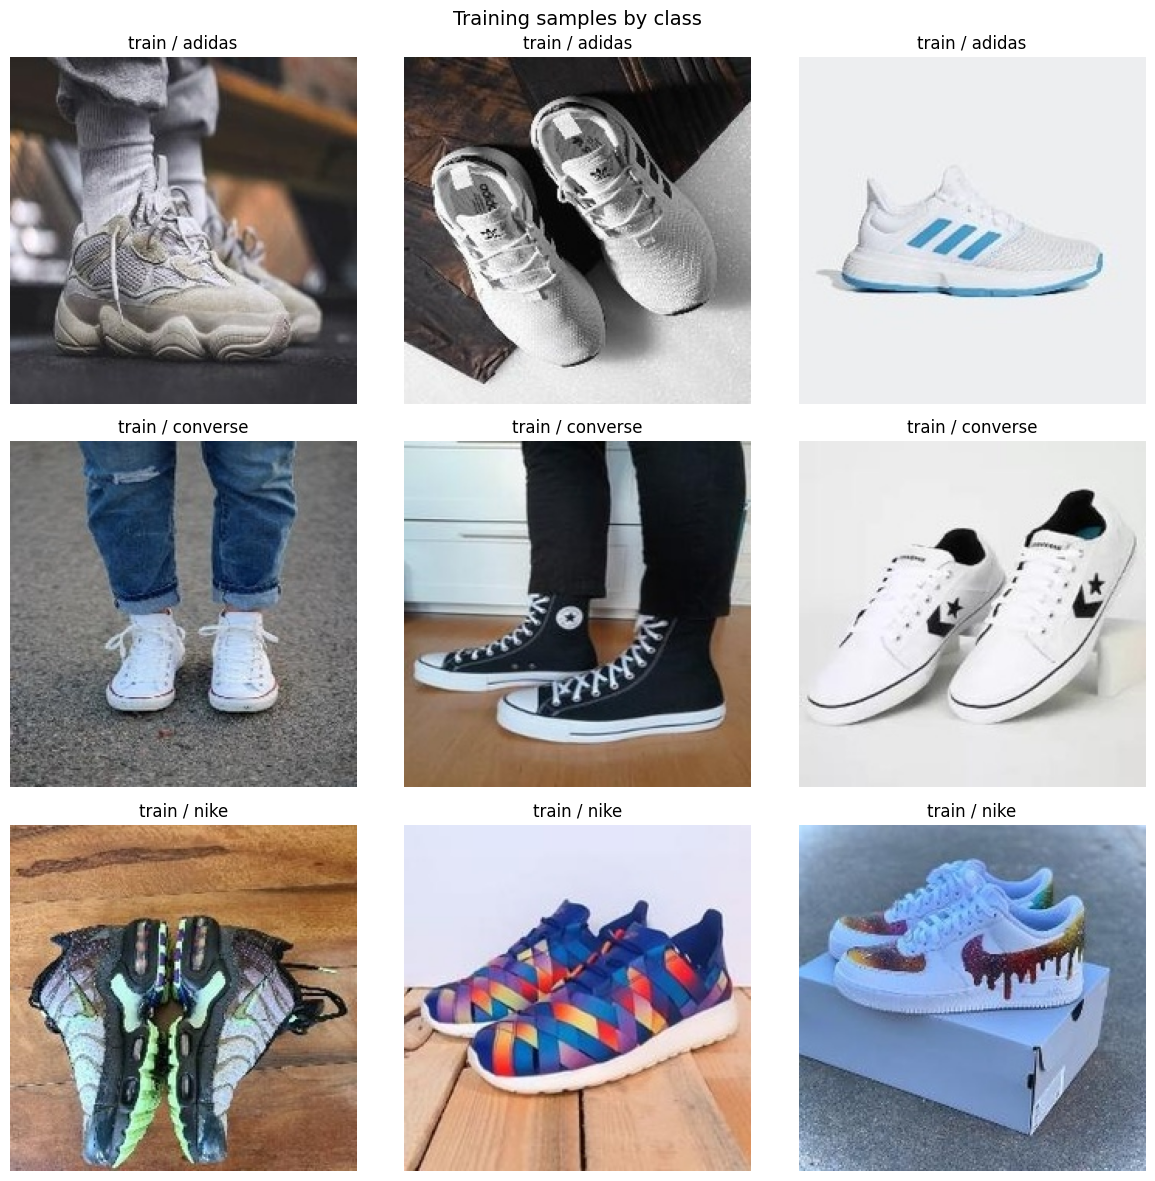

In [8]:
def show_image_grid(rows: pd.DataFrame, title: str, columns: int = 3) -> None:
    if rows.empty:
        print(f"No images available for: {title}")
        return

    row_count = int(np.ceil(len(rows) / columns))
    figure, axes = plt.subplots(row_count, columns, figsize=(4 * columns, 4 * row_count), squeeze=False)
    for axis, (_, row) in zip(axes.flat, rows.iterrows()):
        with Image.open(row["path"]) as image:
            axis.imshow(image)
        axis.set_title(f"{row['split']} / {row['class_name']}")
        axis.axis("off")
    for axis in axes.flat[len(rows):]:
        axis.axis("off")
    figure.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


training_samples = (
    metadata[metadata["split"] == "train"]
    .groupby("class_name", group_keys=False)
    .sample(n=3, random_state=RANDOM_SEED)
)
show_image_grid(training_samples, "Training samples by class")

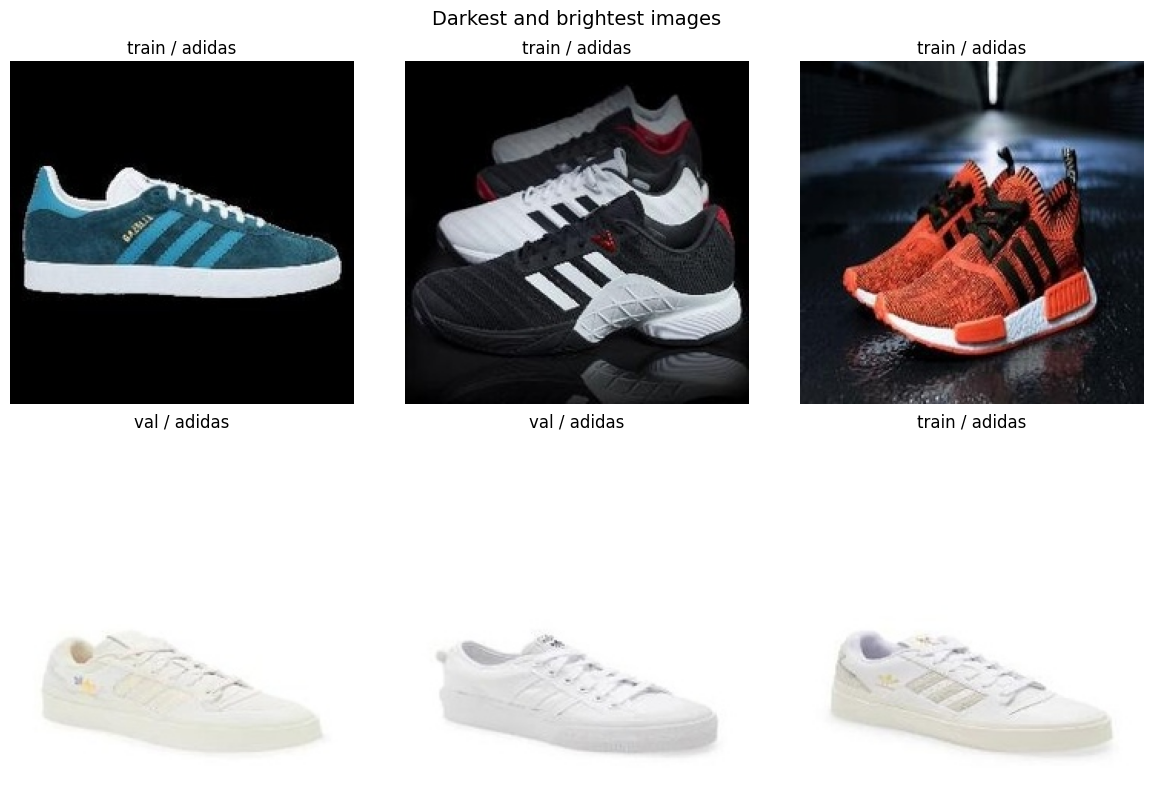

In [9]:
extreme_brightness_samples = pd.concat([
    metadata.nsmallest(3, "brightness"),
    metadata.nlargest(3, "brightness"),
])
show_image_grid(extreme_brightness_samples, "Darkest and brightest images")

## Exact duplicates and split leakage

In [10]:
duplicate_hashes = metadata[metadata.duplicated("sha256", keep=False)].sort_values("sha256")
duplicate_groups = duplicate_hashes["sha256"].nunique()
duplicate_files = len(duplicate_hashes)

cross_split_hashes = (
    metadata.groupby("sha256")["split"].nunique().loc[lambda values: values > 1].index
)
cross_split_duplicates = metadata[metadata["sha256"].isin(cross_split_hashes)].sort_values("sha256")

print(f"Exact duplicate groups: {duplicate_groups}")
print(f"Files belonging to duplicate groups: {duplicate_files}")
print(f"Exact duplicate groups crossing splits: {len(cross_split_hashes)}")
if not cross_split_duplicates.empty:
    display(cross_split_duplicates[["split", "class_name", "file_name", "sha256"]])

Exact duplicate groups: 0
Files belonging to duplicate groups: 0
Exact duplicate groups crossing splits: 0


## EDA summary and recommendations

In [11]:
print("EDA SUMMARY")
print(f"- Total readable images: {len(metadata)}")
print(f"- Corrupt images: {len(corrupt_files)}")
print(f"- Unique resolutions: {metadata[['width', 'height']].drop_duplicates().shape[0]}")
print(f"- Missing classes by split: {missing_classes or 'none'}")
print(f"- Exact duplicate groups: {duplicate_groups}")
print(f"- Cross-split duplicate groups: {len(cross_split_hashes)}")
print("- Stratified split status: ready for model setup.")
print("- Recommendation: keep the fixed random seed to preserve reproducible evaluation.")

EDA SUMMARY
- Total readable images: 825
- Corrupt images: 0
- Unique resolutions: 1
- Missing classes by split: none
- Exact duplicate groups: 0
- Cross-split duplicate groups: 0
- Stratified split status: ready for model setup.
- Recommendation: keep the fixed random seed to preserve reproducible evaluation.
